# 04 - Gaussian elimination: node voltages and conditioning

**Goal.** Solve a linear system by elimination with partial pivoting, then study when it goes wrong.

**Problem A (my own).** Nodal analysis of a small resistor network. With node 0 as ground, $G\,v = i$, where $G$ is the conductance matrix and $i$ the injected currents.

In [5]:
import sys
sys.path.insert(0, "../src")  # lets this notebook run without installing the package

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (6.5, 3.6), "axes.grid": True})
from scipy.linalg import hilbert

from nummeth import SingularMatrixError, condition_number, determinant, gauss_solve

In [14]:
# Branches as (node a, node b, resistance in ohms); node 0 is ground.
branches = [(1, 2, 100.0), (2, 3, 220), (3, 4, 150.0), (4, 5, 330.0), (1, 5, 470.0),
            (2, 5, 180.0), (0, 1, 1000.0), (0, 3, 680.0), (0, 4, 470.0)]
n = 5
G = np.zeros((n, n))
for a, b, ohms in branches:
    g = 1.0 / ohms
    if a > 0: G[a - 1, a - 1] += g
    if b > 0: G[b - 1, b - 1] += g
    if a > 0 and b > 0:
        G[a - 1, b - 1] -= g
        G[b - 1, a - 1] -= g

i_inj = np.array([5e-3, 0.0, 0.0, 2e-3, 0.0])  # 5 mA into node 1, 2 mA into node 4

v = gauss_solve(G, i_inj)
v_np = np.linalg.solve(G, i_inj)
print("node voltages (V):", np.round(v, 5))
print("max difference vs numpy.linalg.solve:", np.max(np.abs(v - v_np)))
print("KCL residual (A):", np.max(np.abs(G @ v - i_inj)))
print("det(G) mine / numpy:", determinant(G), np.linalg.det(G))

node voltages (V): [2.03101 1.79856 1.37328 1.38625 1.7281 ]
max difference vs numpy.linalg.solve: 1.7763568394002505e-15
KCL residual (A): 3.4117981476311037e-18
det(G) mine / numpy: 4.081483688205178e-11 4.0814836882051825e-11


## Why pivot?

The system below has a tiny leading entry. Without pivoting, elimination divides by $10^{-20}$ and destroys the answer. The true solution is very close to $x = (1, 1)$.

In [7]:
A = [[1e-20, 1.0], [1.0, 1.0]]
b = [1.0, 2.0]
print("numpy            :", np.linalg.solve(A, b))
print("mine, pivoting   :", gauss_solve(A, b))
print("mine, no pivoting:", gauss_solve(A, b, pivoting=False))

numpy            : [1. 1.]
mine, pivoting   : [1. 1.]
mine, no pivoting: [0. 1.]


## Conditioning

The Hilbert matrix $H_{ij} = 1/(i + j - 1)$ is notoriously ill-conditioned. Solve $H x = H\mathbf{1}$, whose exact solution is all ones, and watch the error grow with the 1-norm condition number $\kappa$.

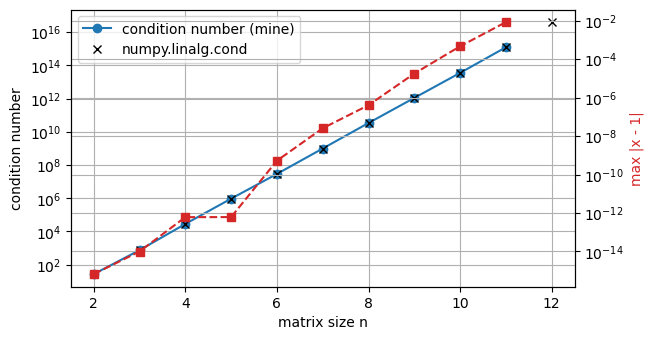

n =  2  kappa(numpy) =  2.70e+01  error =  6.66e-16
n =  3  kappa(numpy) =  7.48e+02  error =  9.99e-15
n =  4  kappa(numpy) =  2.84e+04  error =  6.11e-13
n =  5  kappa(numpy) =  9.44e+05  error =  6.17e-13
n =  6  kappa(numpy) =  2.91e+07  error =  5.26e-10
n =  7  kappa(numpy) =  9.85e+08  error =  2.57e-08
n =  8  kappa(numpy) =  3.39e+10  error =  4.06e-07
n =  9  kappa(numpy) =  1.10e+12  error =  1.80e-05
n = 10  kappa(numpy) =  3.54e+13  error =  4.69e-04
n = 11  kappa(numpy) =  1.23e+15  error =  8.48e-03
n = 12  kappa(numpy) =  4.02e+16  solver flagged the matrix as singular


In [8]:
sizes = list(range(2, 13))
conds, errs = [], []
for m in sizes:
    H = hilbert(m)
    try:
        x = gauss_solve(H, H @ np.ones(m))
        errs.append(np.max(np.abs(x - 1.0)))
    except SingularMatrixError:
        errs.append(np.nan)  # elimination met a pivot below the solver's tolerance
    conds.append(condition_number(H))  # inf when the inverse cannot be formed

fig, ax1 = plt.subplots()
ax1.semilogy(sizes, conds, "o-", color="tab:blue", label="condition number (mine)")
ax1.semilogy(sizes, [np.linalg.cond(hilbert(m), 1) for m in sizes], "x", color="k", label="numpy.linalg.cond")
ax1.set_xlabel("matrix size n"); ax1.set_ylabel("condition number"); ax1.legend(loc="upper left")
ax2 = ax1.twinx()
ax2.semilogy(sizes, errs, "s--", color="tab:red", label="error in x")
ax2.set_ylabel("max |x - 1|", color="tab:red")
plt.show()

for m, k, e in zip(sizes, conds, errs):
    status = f"error = {e:9.2e}" if np.isfinite(e) else "solver flagged the matrix as singular"
    print(f"n = {m:>2}  kappa(numpy) = {np.linalg.cond(hilbert(m), 1):9.2e}  {status}")

In [ ]:
# Sensitivity check: change the 100-ohm branch (nodes 1-2) by +1% and re-solve
cond_G = condition_number(G)
branches_1pct = [(a, b, ohms * 1.01 if (a, b) == (1, 2) else ohms) for a, b, ohms in branches]
G1 = np.zeros((n, n))
for a, b, ohms in branches_1pct:
    g = 1.0 / ohms
    if a > 0: G1[a - 1, a - 1] += g
    if b > 0: G1[b - 1, b - 1] += g
    if a > 0 and b > 0:
        G1[a - 1, b - 1] -= g
        G1[b - 1, a - 1] -= g
v_1pct = gauss_solve(G1, i_inj)
print(f"condition number of G (1-norm): {cond_G:.1f}")
print(f"largest relative change in a node voltage for a 1% resistor change: {np.max(np.abs(v_1pct - v) / np.abs(v)) * 100:.3f}%")

condition number of G (1-norm): 51.9
largest relative change in a node voltage for a 1% resistor change: 0.059%


## Observations

- How does the error grow with the condition number? Compare with $\kappa \cdot \varepsilon$, where $\varepsilon$ is machine epsilon.
- At one size the solver refuses the matrix even though a Hilbert matrix is not singular. Why? (Hint: compare the pivot tolerance with $\kappa \cdot \varepsilon$.)
- Change a resistor value in the network by 1%. How much do the node voltages move?

The error grows as the condition number grows: from n = 2 to n = 11 the error rises from about 7e-16 to 8e-3 while kappa rises from 27 to 1.2e15. The error stays below kappa times epsilon (epsilon is about 2.2e-16): at n = 6, kappa*eps is about 6.5e-9 against a measured error of 5e-10, and at n = 11 it is about 0.27 against 8.5e-3. So kappa*eps is a worst-case estimate, and the real error is one to two orders of magnitude smaller.

For the resistor network, the new cell above shows a condition number of about 52, and a 1% change in the 100-ohm resistor moves the node voltages by only about 0.06%. So the matrix is well-conditioned.

At n = 12, kappa*eps is about 9, which is greater than 1, so a computed solution would have no correct digits. The Hilbert matrix is not singular mathematically, but it is numerically singular in finite-precision arithmetic, and the solver's pivot tolerance refuses it.